# Practice guide 03_01: classic anomaly detectors on network connections

**Goal.** Build the statistical core of an anomaly detector yourself (z-score, Mahalanobis distance, a threshold set
on normal data, average precision), compare it with the scikit-learn twins, run the classic detectors on KDD99, and
measure why a classifier is not enough for new attacks. Every `TODO` cell must be completed; the `check` cells tell
you whether you got it right.

Read `guide_03_01.pdf` first. Time: about 2 hours. Cells marked **(given)** are complete.

In [1]:
import sys
from pathlib import Path

import numpy as np
import polars as pl
from sklearn.covariance import EmpiricalCovariance, LedoitWolf
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score

LIB = next(p for p in (Path("../../notebooks/02-anomaly"), Path("../../../notebooks/02-anomaly")) if p.exists())
sys.path.insert(0, str(LIB))  # student / solution folder
import anomlib as an

an.table_config()

## Part A. Example 1 and KDD99 (given)

Example 1: 500 sessions of one host, $x_1$ = log bytes sent, $x_2$ = log bytes received (standardised, correlation
0.9). Point A $=(2,2)$, point B $=(1,-1)$. KDD99: deduplicated, normal rows split 60/20/20, the test set holds 100
attacks per category (u2r: 26), 1.8% of the rows.

In [5]:
X1 = an.example1(500, seed=0)
A, B = an.EX1_POINTS["A"], an.EX1_POINTS["B"]
sp = an.kdd_split(seed=0)
Xtr, Xva, Xte, y = sp.X("train"), sp.X("val"), sp.X("test"), sp.y_test
cats = sp.test["category"]
print("Example 1:", X1.shape, " KDD99 train/val/test:", Xtr.shape, Xva.shape, Xte.shape, " attacks in test:", int(y.sum()))

Example 1: (500, 2)  KDD99 train/val/test: (52698, 71) (17566, 71) (17893, 71)  attacks in test: 326


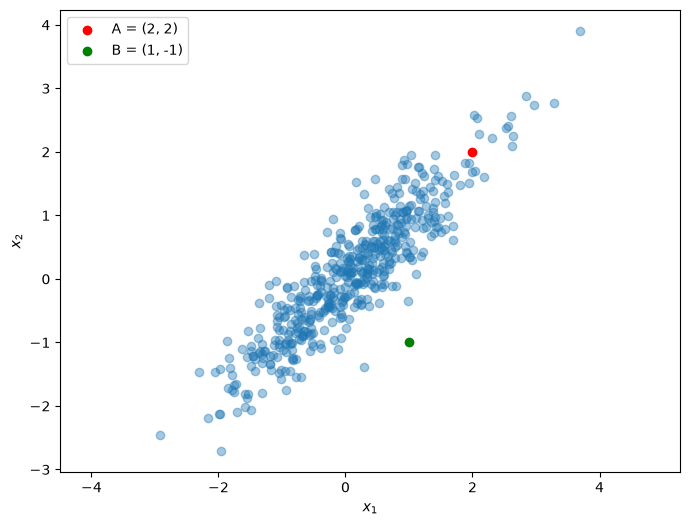

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(X1[:, 0], X1[:, 1], alpha=0.4)
plt.scatter(A[0], A[1], color="red", label="A = (2, 2)")
plt.scatter(B[0], B[1], color="green", label="B = (1, -1)")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.axis("equal")
plt.legend()
plt.show()

## Part B. z-score and Mahalanobis distance

Implement
* `zmax(X, mu, sd)`: for each row, $\max_j |x_j-\mu_j|/\sigma_j$;
* `mahalanobis2(X, mu, cov)`: for each row, $(\mathbf{x}-\boldsymbol\mu)^\top C^{-1}(\mathbf{x}-\boldsymbol\mu)$.

Use `np.linalg.inv` (or better, `np.linalg.solve`) and `np.einsum("ij,jk,ik->i", D, P, D)` to avoid a loop.

In [3]:
def zmax(X, mu, sd):
    return np.max(np.abs((X - mu) / sd), axis=1)


def mahalanobis2(X, mu, cov):
    D = X - mu
    Y = np.linalg.solve(cov, D.T).T
    return np.einsum("ij,ij->i", D, Y)

In [4]:
# check: the numbers of the lecture (true parameters) and the scikit-learn twin (estimated parameters)
P2 = np.vstack([A, B])
assert np.allclose(zmax(P2, an.EX1_MU, np.ones(2)), [2, 1])
assert np.allclose(mahalanobis2(P2, an.EX1_MU, an.EX1_COV), [4.2105, 20.0], atol=1e-3)
emp = EmpiricalCovariance().fit(X1)
mine = mahalanobis2(P2, X1.mean(0), np.cov(X1.T, bias=True))
print("mine:", mine.round(3), " scikit-learn:", emp.mahalanobis(P2).round(3))
assert np.allclose(mine, emp.mahalanobis(P2))
print("z-score and Mahalanobis OK")

mine: [ 3.982 21.304]  scikit-learn: [ 3.982 21.304]
z-score and Mahalanobis OK


**Question B1.** Which point does each score flag, and why? Draw (on paper) the contour $\max|z|=2$ and the
ellipse $d_M=3$ over the cloud of Example 1.

## Part C. Threshold and average precision

* `threshold(s_val, fpr)`: the $(1-\text{fpr})$ quantile of the scores of **normal** validation rows.
* `average_precision(y, s)`: sort by score (highest first); at the rank of each attack compute the precision of the
  top-ranked rows; return the mean of those precisions. It must match `average_precision_score`.
* `precision_at_base_rate(tpr, fpr, b)`: Bayes' rule of the lecture.

In [7]:
def threshold(s_val, fpr=0.01):
    return float(np.quantile(s_val, 1 - fpr))


def average_precision(y, s):
    order = np.argsort(-s, kind="stable")
    hits = y[order]
    precision_at_k = np.cumsum(hits) / np.arange(1, len(hits) + 1)
    return float(precision_at_k[hits == 1].mean())


def precision_at_base_rate(tpr, fpr, b):
    return tpr * b / (tpr * b + fpr * (1 - b))

In [8]:
# check
rng = np.random.default_rng(0)
yy, ss = (rng.random(2000) < 0.05).astype(int), rng.random(2000)
ss[yy == 1] += 0.3
assert abs(average_precision(yy, ss) - average_precision_score(yy, ss)) < 1e-9
assert abs(threshold(np.arange(101.0), 0.01) - 99.0) < 1e-9
assert abs(precision_at_base_rate(0.95, 0.01, 1e-4) - 0.0094) < 1e-4
print("threshold, AP and base rate OK")

threshold, AP and base rate OK


**Question C1.** Fill the table for TPR = 0.95. How many of 100 alarms are real at $b$ = 1/10,000 and FPR = 1%?

In [9]:
print(pl.DataFrame([{"base rate": f"1/{round(1 / b):,}", **{f"FPR {f}": precision_at_base_rate(0.95, f, b) for f in [0.01, 0.001]}}
                    for b in [1e-2, 1e-3, 1e-4]]))  # fmt: skip

┌───────────┬──────────┬───────────┐
│ base rate ┆ FPR 0.01 ┆ FPR 0.001 │
╞═══════════╪══════════╪═══════════╡
│ 1/100     ┆ 0.490    ┆ 0.906     │
│ 1/1,000   ┆ 0.087    ┆ 0.487     │
│ 1/10,000  ┆ 0.009    ┆ 0.087     │
└───────────┴──────────┴───────────┘


## Part D. Mahalanobis on KDD99, and the classic zoo

With 71 features (many one-hot columns) the sample covariance is singular. **Shrink** it:
$\hat C=(1-\lambda)S+\lambda\,\frac{\text{tr}(S)}{d}I$. Implement `fit_shrunk(X, lam)` returning
$(\boldsymbol\mu,\hat C)$; then compare $\lambda=0.01, 0.1$ with scikit-learn's `LedoitWolf` (which picks
$\lambda$ from the data).

In [12]:
def fit_shrunk(X, lam):

    """Estimate a covariance matrix using linear shrinkage.

    Parameters
    ----------
    X : array-like of shape (n_samples, n_features)
        Observations, with one observation per row.
    lam : float
        Shrinkage intensity, between 0 and 1.

    Returns
    -------
    covariance : array-like of shape (n_features, n_features)
        Estimated covariance matrix."""
    
    X = np.asarray(X, dtype=float)

    n_samples, n_features = X.shape

   # Mean of each feature.
    mu = X.mean(axis=0)

    # Center every observation around the feature means.
    X_centered = X - mu

    # Empirical sample covariance.
    cov = (
        X_centered.T @ X_centered
    ) / (n_samples - 1)

    # Spherical shrinkage target.
    target = (
        np.trace(cov) / n_features
    ) * np.eye(n_features)

    # Combine observed covariance with the stable target.
    shrunk_cov = (1 - lam) * cov + lam * target

    return mu, shrunk_cov

In [13]:
# check and comparison with the twin (given)
rows = []
for lam in [0.01, 0.1]:
    mu, cov = fit_shrunk(Xtr, lam)
    rows.append({"model": f"mine, lambda={lam}", **an.evaluate(mahalanobis2(Xte, mu, cov), y, mahalanobis2(Xva, mu, cov))})
lw = LedoitWolf().fit(Xtr)
rows.append({"model": f"LedoitWolf, lambda={lw.shrinkage_:.4f}", **an.evaluate(lw.mahalanobis(Xte), y, lw.mahalanobis(Xva))})
print(pl.DataFrame(rows))

┌───────────────────────────┬───────┬───────┬────────┬───────────┬───────┬───────┐
│ model                     ┆ AUROC ┆ AUPRC ┆ recall ┆ precision ┆ F1    ┆ FPR   │
╞═══════════════════════════╪═══════╪═══════╪════════╪═══════════╪═══════╪═══════╡
│ mine, lambda=0.01         ┆ 0.980 ┆ 0.539 ┆ 0.742  ┆ 0.537     ┆ 0.623 ┆ 0.012 │
│ mine, lambda=0.1          ┆ 0.978 ┆ 0.498 ┆ 0.571  ┆ 0.467     ┆ 0.514 ┆ 0.012 │
│ LedoitWolf, lambda=0.0606 ┆ 0.979 ┆ 0.516 ┆ 0.681  ┆ 0.516     ┆ 0.587 ┆ 0.012 │
└───────────────────────────┴───────┴───────┴────────┴───────────┴───────┴───────┘


Now the zoo of the lecture (given): ten detectors, one protocol. Copy the AUPRC and the recall per category into
your notes.

In [14]:
rows = []
for det in an.zoo(seed=0):
    det.fit(Xtr)
    s_va, s_te = det.score(Xva), det.score(Xte)
    rows.append({"detector": det.name, **an.evaluate(s_te, y, s_va), **an.recall_by_category(s_te, cats, s_va)})
print(pl.DataFrame(rows).sort("AUPRC", descending=True))

┌───────────────────────┬───────┬───────┬────────┬───────────┬───────┬───────┬───────┬───────┬───────┬───────┐
│ detector              ┆ AUROC ┆ AUPRC ┆ recall ┆ precision ┆ F1    ┆ FPR   ┆ dos   ┆ probe ┆ r2l   ┆ u2r   │
╞═══════════════════════╪═══════╪═══════╪════════╪═══════════╪═══════╪═══════╪═══════╪═══════╪═══════╪═══════╡
│ GMM (-log-likelihood) ┆ 0.982 ┆ 0.675 ┆ 0.702  ┆ 0.543     ┆ 0.612 ┆ 0.011 ┆ 1.000 ┆ 0.850 ┆ 0.250 ┆ 0.731 │
│ One-class SVM         ┆ 0.980 ┆ 0.625 ┆ 0.721  ┆ 0.523     ┆ 0.606 ┆ 0.012 ┆ 1.000 ┆ 0.920 ┆ 0.240 ┆ 0.731 │
│ Isolation Forest      ┆ 0.943 ┆ 0.622 ┆ 0.592  ┆ 0.479     ┆ 0.529 ┆ 0.012 ┆ 0.960 ┆ 0.890 ┆ 0.060 ┆ 0.077 │
│ kNN distance          ┆ 0.989 ┆ 0.595 ┆ 0.715  ┆ 0.547     ┆ 0.620 ┆ 0.011 ┆ 0.990 ┆ 0.930 ┆ 0.220 ┆ 0.731 │
│ PCA reconstruction    ┆ 0.982 ┆ 0.549 ┆ 0.776  ┆ 0.541     ┆ 0.637 ┆ 0.012 ┆ 0.970 ┆ 0.880 ┆ 0.450 ┆ 0.885 │
│ Mahalanobis           ┆ 0.979 ┆ 0.516 ┆ 0.681  ┆ 0.516     ┆ 0.587 ┆ 0.012 ┆ 0.990 ┆ 0.670 ┆ 0.370 ┆ 0.731 │
│

**Question D1.** Which category is hard for every detector, and why? Which detector misses most DoS rows, and why
does a flood fool it? **D2.** How does the shrinkage $\lambda$ change the result, and what does `LedoitWolf` choose?

## Part E. The Isolation Forest score

Implement `c(n)` $=2H(n-1)-2(n-1)/n$ with $H(i)=\ln i+0.5772156649$, and `iforest_score(mean_depth, n)`
$=2^{-\text{mean\_depth}/c(n)}$.

In [17]:
import math
def c(n):
    return 2 * (math.log(n - 1) + 0.5772156649) - 2 * (n - 1) / n


def iforest_score(mean_depth, n=256):
    return 2 ** (-mean_depth / c(n))

In [22]:
# check
assert abs(c(256) - 10.2448) < 1e-3
assert abs(iforest_score(c(256)) - 0.5) < 1e-12
print("c(256) =", round(c(256), 3), " score after 4 cuts:", round(float(iforest_score(4)), 3))

c(256) = 10.245  score after 4 cuts: 0.763


**Question E1.** What score does a point get when it is isolated after 2 cuts? After 20? Why do the trees use small
subsamples (256 rows)?

## Part F. A classifier or a one-class detector?

Implement `train_without(category)`: a random forest (200 trees, `random_state=0`, `n_jobs=-1`) trained on the
normal training rows (label 0) and the attack pool **without** `category` (label 1). Return the recall on the
test attacks of that category at the 1% validation threshold (use `an.recall_by_category`).

In [23]:
Xp, cp = sp.X("pool"), sp.pool["category"].to_numpy()


def train_without(category):
    keep = cp != category

    X = np.vstack([Xtr, Xp[keep]])
    labels = np.r_[
        np.zeros(len(Xtr)),
        np.ones(keep.sum()),
    ]

    rf = RandomForestClassifier(
        200,
        random_state=0,
        n_jobs=-1,
    ).fit(X, labels)

    s_va = rf.predict_proba(Xva)[:, 1]
    s_te = rf.predict_proba(Xte)[:, 1]

    recalls = an.recall_by_category(s_te, cats, s_va)
    return recalls[category]

In [24]:
# driver (given)
pca = an.PCARecon().fit(Xtr)
one_class = an.recall_by_category(pca.score(Xte), cats, pca.score(Xva))
print(pl.DataFrame([{"unseen category": cat, "random forest": train_without(cat), "PCA (one-class)": one_class[cat]}
                    for cat in an.CATEGORIES]))  # fmt: skip

┌─────────────────┬───────────────┬─────────────────┐
│ unseen category ┆ random forest ┆ PCA (one-class) │
╞═════════════════╪═══════════════╪═════════════════╡
│ dos             ┆ 1.000         ┆ 0.970           │
│ probe           ┆ 1.000         ┆ 0.880           │
│ r2l             ┆ 0.360         ┆ 0.450           │
│ u2r             ┆ 0.962         ┆ 0.885           │
└─────────────────┴───────────────┴─────────────────┘


**Question F1.** For which unseen category does the forest fail, and why? What does that say about deploying only a
classifier? **F2.** Propose a combination of the two kinds of detector for a real network.